# Summary of Imaging Analyses Results

__This notebook also merge all the imaging analyses results together and output.__

In [43]:
# imports
import os
import polars as pl
import pandas as pd
import numpy as np
from tqdm import tqdm
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import umap
from functools import reduce
import operator
from adjustText import adjust_text
import sys
sys.path.append("../../../../1_allele_collection/2_analysis")
from plot_utils import *
sys.path.append("../1_snakemake_pipeline/2025_varchamp_snakemake")
from img_utils import *

sns.set_style(style='white')
sns.set_context("notebook", font_scale=.9)

In [44]:
ALLELE_COLLECTION_INFO = "../../../../1_allele_collection/3_outputs"
GFP_MISLOCAL_FEAT = "Altered_95th_perc_both_batches_GFP"

## 1. Loading Data

### 1.1 Metadata

In [45]:
clin_var_df = pl.read_csv(f"{ALLELE_COLLECTION_INFO}/varchamp_seq_confirm_alleles_clinvar_gnomad_dbnsfp_struc_scores_OMIM_MOI_disease_modules.tsv", 
                          separator="\t", infer_schema_length=10000
).with_columns(
    pl.col("symbol").str.replace_all(r"[^a-zA-Z0-9]", "").alias("symbol")
).with_columns(
    pl.concat_str([pl.col("symbol"),pl.col("aa_change")], separator="_").alias("gene_allele"),
)

### 1.2 Imaging Analysis

In [46]:
cell_count_summary = pl.read_csv(f"{CC_ABUND_DIR}/cell_count_diff_summary.csv").rename(
    {"Variant": "gene_allele"}
)
prot_abund_summary = pl.read_csv(f"{CC_ABUND_DIR}/prot_abundance_diff_summary.csv").rename(
    {"Variant": "gene_allele"}
)
auroc_summary_df = pl.read_csv(f"{CLASS_SUMMARY_DIR}/imaging_analyses_classification_summary_one_perc.csv")

In [50]:
auroc_summary_df

symbol,gene_allele,Metadata_Bio_Batch,Altered_95th_perc_both_batches_GFP,Altered_95th_perc_both_batches_DNA,Altered_95th_perc_both_batches_Mito,Altered_95th_perc_both_batches_AGP,Altered_95th_perc_both_batches_Morph,Altered_99th_perc_both_batches_GFP,Altered_99th_perc_both_batches_DNA,Altered_99th_perc_both_batches_Mito,Altered_99th_perc_both_batches_AGP,Altered_99th_perc_both_batches_Morph,AUROC_Mean_GFP,AUROC_Mean_DNA,AUROC_Mean_Mito,AUROC_Mean_AGP,AUROC_Mean_Morph,AUROC_BioRep1_Morph,AUROC_BioRep1_AGP,AUROC_BioRep1_Mito,AUROC_BioRep1_DNA,AUROC_BioRep1_GFP,AUROC_BioRep2_Morph,AUROC_BioRep2_AGP,AUROC_BioRep2_Mito,AUROC_BioRep2_DNA,AUROC_BioRep2_GFP
str,str,str,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""BRAF""","""BRAF_Lys499Asn""","""2025_01_Batch_13-14""",false,false,false,false,false,false,false,false,false,false,0.751505,0.56185,0.725234,0.704712,0.662407,0.663304,0.699625,0.762387,0.54426,0.771352,0.66151,0.709799,0.688081,0.57944,0.731657
"""CTCF""","""CTCF_Tyr407Cys""","""2025_01_Batch_13-14""",false,false,false,false,false,false,false,false,false,false,0.653493,0.587955,0.704138,0.733873,0.645128,0.583208,0.806252,0.657896,0.575567,0.688177,0.707047,0.661494,0.750381,0.600343,0.618809
"""BCL10""","""BCL10_Ala5Ser""","""2025_01_Batch_13-14""",false,false,false,false,false,false,false,false,false,false,0.775557,0.647788,0.767403,0.768018,0.784561,0.800741,0.707529,0.722678,0.754122,0.784466,0.768381,0.828507,0.812128,0.541453,0.766648
"""FARS2""","""FARS2_Asp325Tyr""","""2025_01_Batch_13-14""",false,false,false,false,false,false,false,false,false,false,0.730254,0.68332,0.693254,0.716659,0.716551,0.787532,0.722413,0.680545,0.762253,0.746062,0.64557,0.710905,0.705963,0.604386,0.714446
"""RAD51D""","""RAD51D_Arg55Trp""","""2025_01_Batch_13-14""",false,false,false,false,false,false,false,false,false,false,0.717544,0.547243,0.662655,0.721688,0.55859,0.577305,0.731021,0.661531,0.56697,0.731384,0.539875,0.712355,0.663779,0.527515,0.703705
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""COMP""","""COMP_Cys348Arg""","""2024_01_Batch_7-8""",false,false,false,false,false,false,false,false,false,false,0.878607,0.885403,0.867017,0.781096,0.912494,0.912494,0.853675,0.897148,0.885403,0.923016,null,0.708517,0.836885,null,0.834198
"""GCK""","""GCK_Arg377His""","""2024_01_Batch_7-8""",false,false,false,false,false,false,false,false,false,false,0.759726,0.557682,0.689029,0.702714,0.582422,0.582422,0.702714,0.689029,0.557682,0.759726,null,null,null,null,null
"""GCK""","""GCK_Gly175Arg""","""2024_01_Batch_7-8""",false,false,false,false,false,false,false,false,false,false,0.88123,0.689025,0.835236,0.786208,0.717702,0.717702,0.786208,0.835236,0.689025,0.88123,null,null,null,null,null


In [47]:
# with pl.Config(set_tbl_rows=60):
#     display(auroc_summary_df.filter(
#         ~pl.col("gene_allele").is_in(clin_var_df["gene_allele"].unique())
#     ))

# auroc_summary_df.filter(
#     ~pl.col("Gene").is_in(clin_var_df["symbol"].unique())
# )

In [51]:
imaging_summary = cell_count_summary.join(
    prot_abund_summary,
    on=["Gene", "gene_allele"],
    how="full",
    coalesce=True
).join(
    auroc_summary_df,
    left_on=["Gene", "gene_allele"],
    right_on=["symbol", "gene_allele"],
    how="full",
    coalesce=True
)
imaging_summary.unique("gene_allele")

Gene,gene_allele,U2OS_cc_t_stat,U2OS_cc_t_pval,U2OS_prot_abun_t_stat,U2OS_prot_abun_t_pval,Metadata_Bio_Batch,Altered_95th_perc_both_batches_GFP,Altered_95th_perc_both_batches_DNA,Altered_95th_perc_both_batches_Mito,Altered_95th_perc_both_batches_AGP,Altered_95th_perc_both_batches_Morph,Altered_99th_perc_both_batches_GFP,Altered_99th_perc_both_batches_DNA,Altered_99th_perc_both_batches_Mito,Altered_99th_perc_both_batches_AGP,Altered_99th_perc_both_batches_Morph,AUROC_Mean_GFP,AUROC_Mean_DNA,AUROC_Mean_Mito,AUROC_Mean_AGP,AUROC_Mean_Morph,AUROC_BioRep1_Morph,AUROC_BioRep1_AGP,AUROC_BioRep1_Mito,AUROC_BioRep1_DNA,AUROC_BioRep1_GFP,AUROC_BioRep2_Morph,AUROC_BioRep2_AGP,AUROC_BioRep2_Mito,AUROC_BioRep2_DNA,AUROC_BioRep2_GFP
str,str,f64,f64,f64,f64,str,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""GFAP""","""GFAP_Leu235Pro""",-0.260704,0.801824,3.882087,0.006037,"""2025_03_Batch_15-16""",true,false,false,false,false,false,false,false,false,false,0.957791,0.698137,0.866558,0.811097,0.743728,0.690536,0.770895,0.820668,0.687777,0.954828,0.79692,0.851299,0.912448,0.708498,0.960753
"""BRCA1""","""BRCA1_Cys64Tyr""",-0.241112,0.816379,-2.269453,0.057524,"""2025_01_Batch_13-14""",false,false,false,true,false,false,false,false,false,false,0.922977,0.805035,0.873185,0.961233,0.930471,0.876778,0.973083,0.759357,0.649112,0.877086,0.984165,0.949384,0.987013,0.960958,0.968868
"""KCNJ2""","""KCNJ2_Arg40Gln""",-6.955616,0.00022,-8.636043,0.000056,"""2025_03_Batch_15-16""",true,true,true,true,true,false,true,false,true,true,0.988352,0.960955,0.982847,0.97633,0.973521,0.972984,0.971045,0.97502,0.961829,0.980569,0.974059,0.981615,0.990675,0.960081,0.996136
"""GFAP""","""GFAP_Asp295Asn""",3.094883,0.017447,-13.192371,0.000003,"""2025_03_Batch_15-16""",true,true,true,true,false,true,true,true,true,false,0.996076,0.953924,0.996329,0.975002,0.885107,0.803649,0.972821,0.995408,0.92416,0.99561,0.966565,0.977183,0.997249,0.983689,0.996542
"""HPRT1""","""HPRT1_Gly70Glu""",-0.421235,0.686216,-2.259379,0.058385,"""2024_01_Batch_7-8""",false,false,false,false,false,false,false,false,false,false,0.893444,0.862926,0.845402,0.814225,0.657097,0.700312,0.865235,0.886085,0.876223,0.916796,0.613882,0.763215,0.804718,0.84963,0.870092
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""NR0B1""","""NR0B1_Arg425Ile""",0.251888,0.808363,2.901029,0.022952,"""2025_03_Batch_15-16""",true,true,true,true,false,true,true,false,true,false,0.993938,0.97542,0.981073,0.959146,0.5881,0.604561,0.951937,0.979312,0.97376,0.99278,0.571639,0.966355,0.982834,0.977079,0.995096
"""DES""","""DES_Arg227Cys""",-3.041404,0.022762,-0.4318,0.678875,"""2024_01_Batch_7-8""",false,false,false,false,false,false,false,false,false,false,0.790064,0.887448,0.907498,0.872636,0.929167,0.986908,0.9713,0.987326,0.974413,0.85397,0.871425,0.773973,0.82767,0.800483,0.726159
"""EIF2B4""","""EIF2B4_Ala228Val""",3.553388,0.009301,null,null,"""2024_01_Batch_7-8""",null,true,true,false,false,null,true,false,false,false,null,0.995244,0.989394,0.985075,0.769305,0.88241,0.979526,0.98864,0.994446,null,0.6562,0.990625,0.990147,0.996043,null


### 1.3 Merge imgaing with ClinVar

In [59]:
imaging_summary_oneperc_clinvar = imaging_summary.filter(
    pl.col("Metadata_Bio_Batch") != "2025_01_Batch_13-14"
).join(
    clin_var_df,
    on="gene_allele",
    how="inner"
).with_columns(
    pl.when(pl.col("clinvar_clnsig_clean").is_null())
    .then(pl.lit("6_No_ClinVar"))
    .otherwise(pl.col("clinvar_clnsig_clean"))
    .alias("clinvar_clnsig_clean")
)

seq_conf_cols = [
    "entry_sequence_confirmation_class",
    "mislocalization_sequence_confirmation_class",
]
imaging_summary_oneperc_clinvar = imaging_summary_oneperc_clinvar.with_columns([
    pl.col(col).cast(pl.Float64, strict=False) for col in seq_conf_cols
])

## Define masks for variant allele filtering
# At least one entry sequence vector is good
any_expression_good = (
    pl.col("entry_sequence_confirmation_class").is_in([1, 2])
)
entry_good = pl.col("mislocalization_sequence_confirmation_class").is_in([1, 2])
entry_null_like = pl.col("mislocalization_sequence_confirmation_class").is_in([7, 99]) | pl.col("mislocalization_sequence_confirmation_class").is_null()
mutant_mask_all = entry_good | (entry_null_like & any_expression_good)

## Combine logic
imaging_summary_oneperc_clinvar = imaging_summary_oneperc_clinvar.filter(
    mutant_mask_all
).unique("gene_allele")

imaging_summary_cava_clinvar = imaging_summary.filter(
    pl.col("Metadata_Bio_Batch") == "2025_01_Batch_13-14"
).join(
    clin_var_df,
    on="gene_allele",
    how="left"
).with_columns(
    pl.when(pl.col("clinvar_clnsig_clean").is_null())
    .then(pl.lit("6_No_ClinVar"))
    .otherwise(pl.col("clinvar_clnsig_clean"))
    .alias("clinvar_clnsig_clean")
).unique("gene_allele")

imaging_summary_clinvar = pl.concat([imaging_summary_oneperc_clinvar, imaging_summary_cava_clinvar])

In [60]:
imaging_summary_clinvar = imaging_summary_clinvar.with_columns(
    pl.col("plddt").cast(pl.Float32).alias("plddt_f32"),
    pl.col("rsa").cast(pl.Float32).alias("rsa_f32"),
)

imaging_summary_clinvar = imaging_summary_clinvar.with_columns(
    (
        pl.when(pl.col("rsa_f32")<.1)
        .then(pl.lit("<10"))
        .when(pl.col("rsa_f32")>=.9)
        .then(pl.lit("$\geqslant$90"))
        .otherwise(pl.lit("10-90"))
    ).alias("RSA_Category"),
    (
        pl.when(pl.col("plddt_f32")<=50)
        .then(pl.lit("<=50"))
        .when((pl.col("plddt_f32")>50)&(pl.col("plddt_f32")<=70))
        .then(pl.lit("50-70"))
        .when((pl.col("plddt_f32")>70)&(pl.col("plddt_f32")<=90))
        .then(pl.lit("70-90"))
        .otherwise(pl.lit(">90"))
    ).alias("pLDDT_Category")
)

In [61]:
imaging_summary_clinvar.write_csv("../../3_outputs/imaging_analyses_summary_clinvar.tsv", separator="\t")
imaging_summary_clinvar.write_csv("../../../../3_integrated_assay_results/1_inputs/imaging_analyses_summary_clinvar.tsv", separator="\t")

In [62]:
imaging_summary_clinvar.filter(pl.col(GFP_MISLOCAL_FEAT)==1).select("AUROC_Mean_GFP","AUROC_BioRep1_GFP", "AUROC_BioRep2_GFP")

AUROC_Mean_GFP,AUROC_BioRep1_GFP,AUROC_BioRep2_GFP
f64,f64,f64
0.93054,0.931336,0.929743
0.997553,0.998808,0.996297
0.994394,0.992452,0.996336
0.981916,0.990437,0.973394
0.994336,0.994099,0.994573
…,…,…
0.973217,0.973217,null
0.977862,0.977862,null
0.996733,0.996189,0.997277


## 2. Data Summary

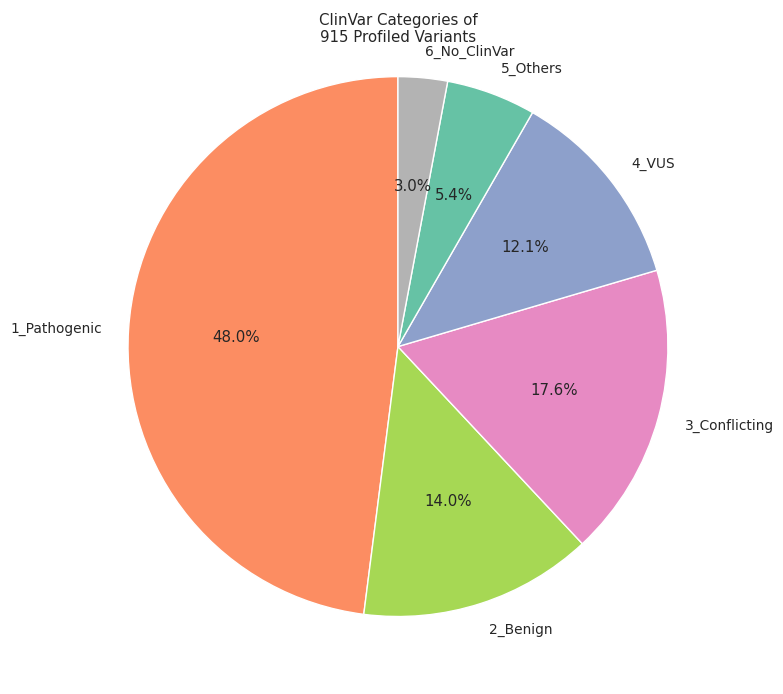

In [63]:
df = imaging_summary_clinvar.to_pandas() ## drop_nulls("clinvar_clnsig_clean").

# Count category frequencies
counts = df["clinvar_clnsig_clean"].value_counts()

# Sort categories if you want specific order
category_order = sorted(df["clinvar_clnsig_clean"].unique())
counts = counts.reindex([cat for cat in category_order if cat in counts.index])
clinvar_palette_old = palette_dict["clinvar_clnsig_clean"]

# Plot pie chart
fig, ax = plt.subplots(figsize=(8, 8))
ax.pie(
    counts,
    labels=counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=clinvar_palette_old.values()
)
ax.set_title(f"ClinVar Categories of\n{df.shape[0]} Profiled Variants",y=.94)
plt.tight_layout()
plt.show()

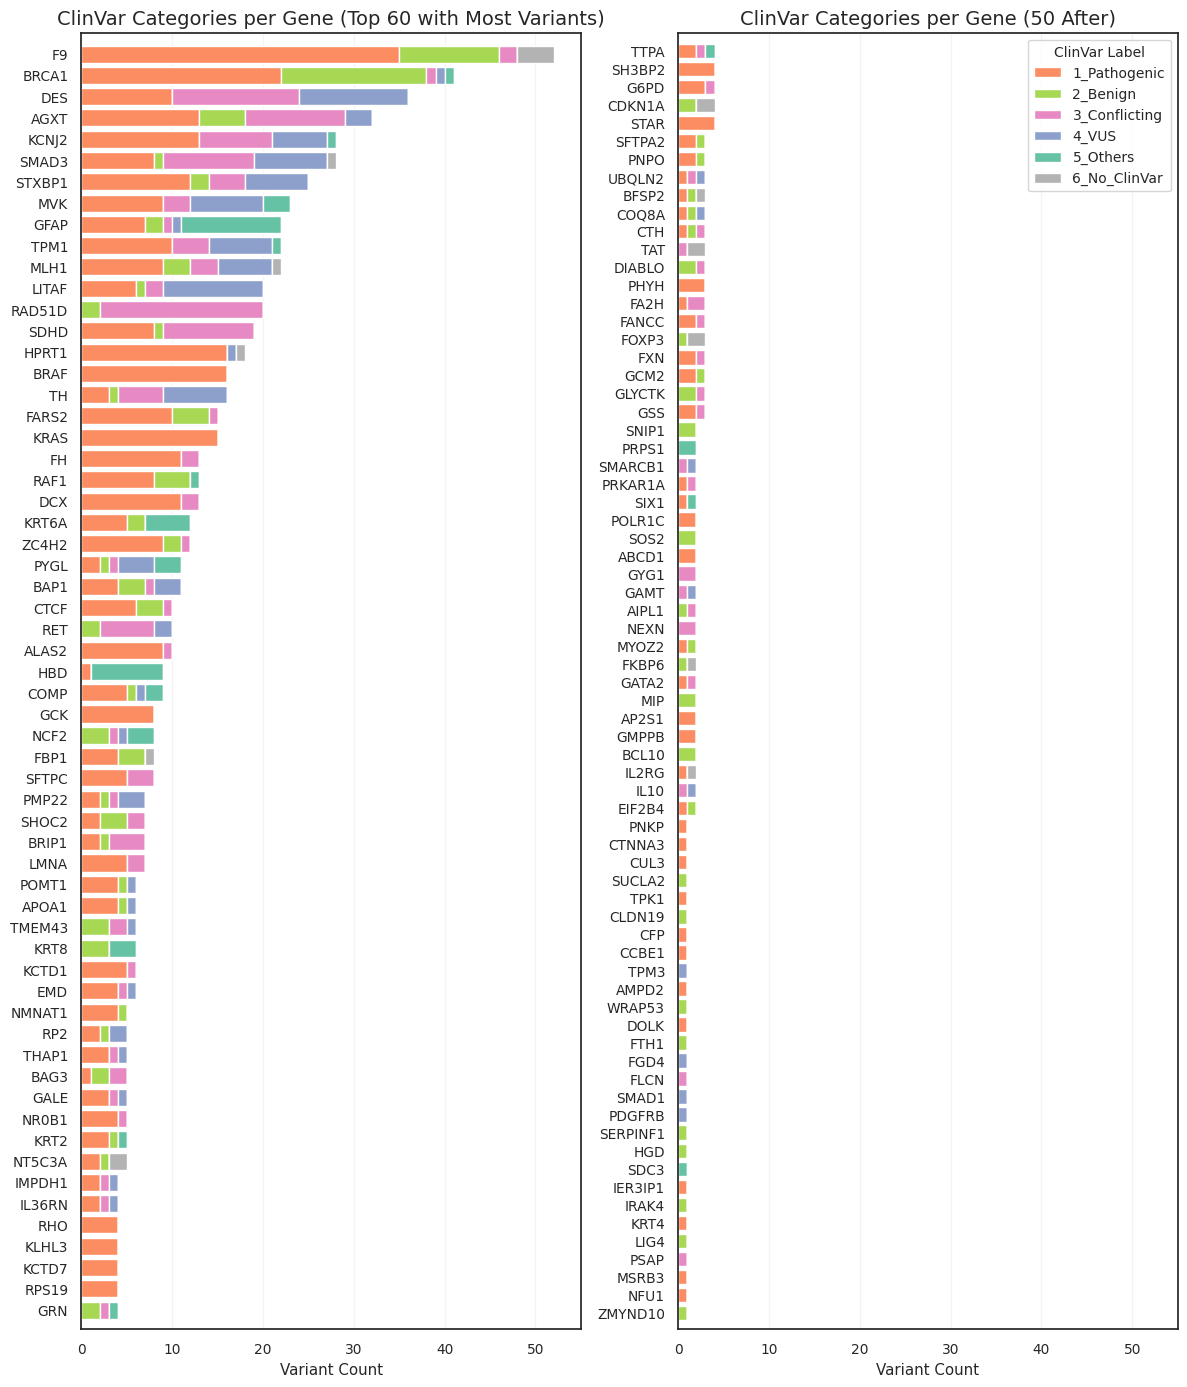

In [64]:
# 2. Count per (gene, category)
top_num = 60
counts = (
    df.groupby(["symbol", "clinvar_clnsig_clean"])
    .size()
    .reset_index(name="count")
)
# 3. Pivot
pivot = counts.pivot(index="symbol", columns="clinvar_clnsig_clean", values="count").fillna(0)

# Add total count column and sort by it (descending)
pivot["total_count"] = pivot.sum(axis=1)
pivot_top = pivot.sort_values("total_count", ascending=False).head(top_num)
pivot_top = pivot_top.drop(columns=["total_count"])
# category_order = sorted(pivot_top["clinvar_clnsig_clean"].unique())

# 4. Ensure category order
for cat in category_order:
    if cat not in pivot_top.columns:
        pivot_top[cat] = 0
pivot_top = pivot_top[category_order]

# 5. Plotting
fig, axes = plt.subplots(1,2, figsize=(12, 14))
# Get Set2 colors
bottom = None
for cat, color in clinvar_palette_old.items():
    axes[0].barh(pivot_top.index, pivot_top[cat], 
            left=bottom, label=cat, color=color)
    bottom = pivot_top[cat] if bottom is None else bottom + pivot_top[cat]
    
# Axis formatting
axes[0].set_xlabel("Variant Count")
axes[0].set_xlim(None, 55)
axes[0].set_ylim(-1, pivot_top.shape[0] - .1)  # Tighten y-axis to remove top/bottom gaps
axes[0].set_title(f"ClinVar Categories per Gene (Top {top_num} with Most Variants)", fontsize=14)
axes[0].invert_yaxis()
axes[0].grid(alpha=.2, axis="x")

# ax.legend(title="ClinVar Label", fontsize=9, title_fontsize=10, loc="lower right")
# plt.tight_layout()
# plt.show()

pivot_bot = pivot.sort_values("total_count", ascending=False).iloc[top_num:,].copy()
pivot_bot = pivot_bot.drop(columns=["total_count"])

# 4. Ensure category order
for cat in category_order:
    if cat not in pivot_bot.columns:
        pivot_bot[cat] = 0
pivot_bot = pivot_bot[category_order]

bottom = None
for cat, color in clinvar_palette_old.items():
    axes[1].barh(pivot_bot.index, pivot_bot[cat], left=bottom, label=cat, color=color)
    bottom = pivot_bot[cat] if bottom is None else bottom + pivot_bot[cat]
    
# Axis formatting
axes[1].set_xlabel("Variant Count")
axes[1].set_xlim(None, 55)
axes[1].set_ylim(-1, pivot_bot.shape[0] - .1)  # Tighten y-axis to remove top/bottom gaps
axes[1].set_title(f"ClinVar Categories per Gene (50 After)", fontsize=14)
axes[1].invert_yaxis()
axes[1].legend(title="ClinVar Label", fontsize=10, title_fontsize=10, loc="upper right")
axes[1].grid(alpha=.2, axis="x")
plt.tight_layout()
plt.show()

## 3. Analyses with different categories

<ipython-input-66-d9d354efef68>:12: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(


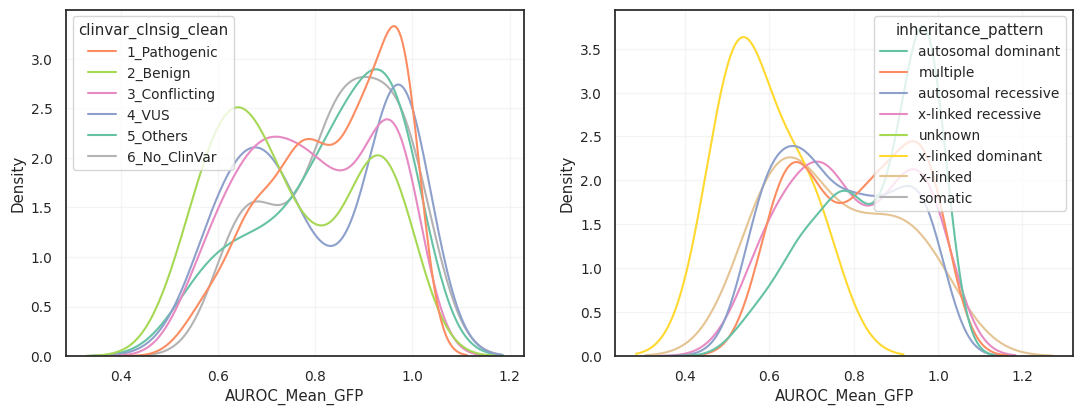

In [66]:
fig, axes = plt.subplots(1,2,figsize=(13, 4.5))
sns.kdeplot(
    data=imaging_summary_clinvar.to_pandas(),
    x="AUROC_Mean_GFP",
    hue="clinvar_clnsig_clean",
    palette=clinvar_palette_old,
    common_norm=False,
    hue_order=sorted(clinvar_palette_old.keys()),
    ax=axes[0]
)
axes[0].grid(alpha=.2)
sns.kdeplot(
    data=imaging_summary_clinvar.to_pandas(),
    x="AUROC_Mean_GFP",
    hue="inheritance_pattern",
    palette="Set2",
    common_norm=False,
    # hue_order=sorted(clinvar_palette_old.keys()),
    ax=axes[1]
)
axes[1].grid(alpha=.2)
plt.show()

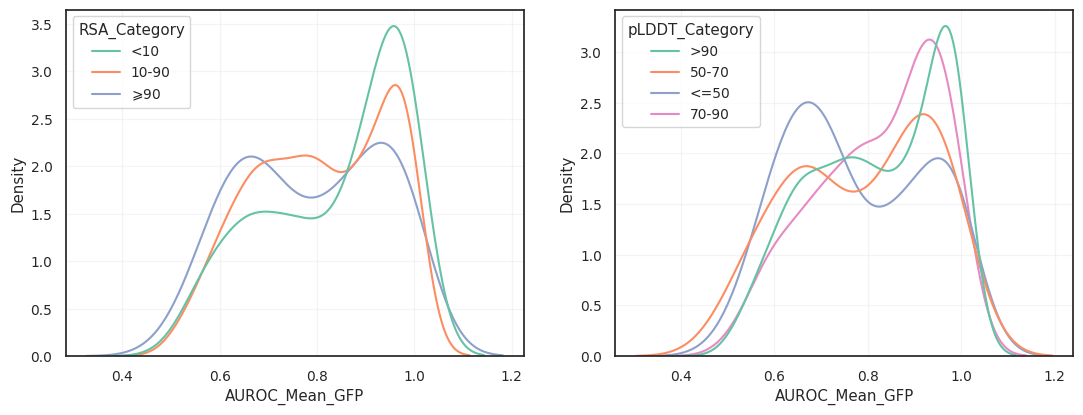

In [67]:
fig, axes = plt.subplots(1,2,figsize=(13, 4.5))
sns.kdeplot(
    data=imaging_summary_clinvar.to_pandas(),
    x="AUROC_Mean_GFP",
    hue="RSA_Category",
    palette="Set2",
    common_norm=False,
    # hue_order=sorted(clinvar_palette_old.keys()),
    ax=axes[0]
)
sns.kdeplot(
    data=imaging_summary_clinvar.to_pandas(),
    x="AUROC_Mean_GFP",
    hue="pLDDT_Category",
    palette="Set2",
    common_norm=False,
    # hue_order=sorted(clinvar_palette_old.keys()),
    ax=axes[1]
)
axes[0].grid(alpha=.2)
axes[1].grid(alpha=.2)
plt.show()

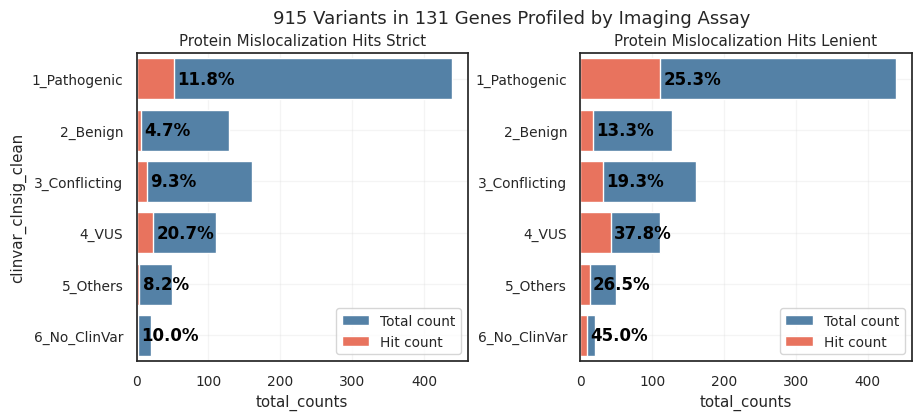

In [69]:
img_metric_df = imaging_summary_clinvar.with_columns(
    (pl.col("Altered_99th_perc_both_batches_GFP")==1).alias("img_prot_hits_5perc_strict"),
    (pl.col(GFP_MISLOCAL_FEAT)==1).alias("img_prot_hits_5perc")
)

img_clinvar_clean_all = img_metric_df.unique("gene_variant").filter(
    pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign","3_Conflicting","4_VUS","5_Others","6_No_ClinVar"]) #pl.col("Gene")!="BRCA1" #
).group_by(
    ["clinvar_clnsig_clean"]
).len().rename(
    {"len": "total_counts"}
)

img_clinvar_clean_hits_prot = img_metric_df.unique("gene_variant").filter(
    (pl.col("img_prot_hits_5perc_strict")) #& (pl.col("Gene")!="BRCA1") #& (pl.col("clinvar_clnsig_clean")#.is_in(["1_Pathogenic","2_Benign","3_Conflicting","4_VUS"]))
).group_by(
    ["clinvar_clnsig_clean"]
).len().rename(
    {"len": "hit_counts"}
)
img_hits_prot = img_clinvar_clean_all.join(
    img_clinvar_clean_hits_prot,
    on=["clinvar_clnsig_clean"],
    how="left"
).fill_null(0).with_columns(
    (pl.col("hit_counts") / pl.col("total_counts") * 100).alias("hit_perc")
)
img_hits_prot.sort("clinvar_clnsig_clean")

fig, axes = plt.subplots(1,2,figsize=(10,4))
plot_df = img_hits_prot.sort("clinvar_clnsig_clean").to_pandas()
sns.barplot(plot_df, y="clinvar_clnsig_clean",
            x="total_counts", color="steelblue",
            label="Total count", ax=axes[0])
sns.barplot(plot_df, y="clinvar_clnsig_clean",
                 x="hit_counts", color="tomato",
                 label="Hit count", ax=axes[0])
axes[0].set_title(f"Protein Mislocalization Hits Strict")
# Add percentage annotations
for i, row in plot_df.iterrows():
    # Position the text at the end of the red (hit_counts) bar
    axes[0].text(row['hit_counts'] + max(plot_df['total_counts']) * 0.01,  # slight offset from bar end
            i,  # y position (bar index)
            f"{row['hit_perc']:.1f}%",  # percentage text
            va='center',  # vertical alignment
            ha='left',   # horizontal alignment
            fontweight='bold',
           fontsize=12,
           color="black")
axes[0].grid(alpha=.2)

img_clinvar_clean_hits_all = img_metric_df.unique("gene_variant").filter(
    (pl.col("img_prot_hits_5perc")) #& (pl.col("Gene")!="BRCA1")  ## (pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign","3_Conflicting","4_VUS"])) & 
).group_by(
    ["clinvar_clnsig_clean"]
).len().rename(
    {"len": "hit_counts"}
)
img_hits_all = img_clinvar_clean_all.join(
    img_clinvar_clean_hits_all,
    on=["clinvar_clnsig_clean"],
    how="left"
).fill_null(0).with_columns(
    (pl.col("hit_counts") / pl.col("total_counts") * 100).alias("hit_perc")
)
plot_df = img_hits_all.sort("clinvar_clnsig_clean").to_pandas()
sns.barplot(plot_df, y="clinvar_clnsig_clean",
            x="total_counts", color="steelblue",
            label="Total count", ax=axes[1])
sns.barplot(plot_df, y="clinvar_clnsig_clean",
                 x="hit_counts", color="tomato",
                 label="Hit count", ax=axes[1])
axes[1].set_title(f"Protein Mislocalization Hits Lenient")
# Add percentage annotations
for i, row in plot_df.iterrows():
    # Position the text at the end of the red (hit_counts) bar
    axes[1].text(row['hit_counts'] + max(plot_df['total_counts']) * 0.01,  # slight offset from bar end
            i,  # y position (bar index)
            f"{row['hit_perc']:.1f}%",  # percentage text
            va='center',  # vertical alignment
            ha='left',   # horizontal alignment
            fontweight='bold',
           fontsize=12,
           color="black")
axes[1].grid(alpha=.2)
axes[1].set_ylabel("")
plt.suptitle(f"{img_metric_df.shape[0]} Variants in {img_metric_df.unique('Gene').shape[0]} Genes Profiled by Imaging Assay", y=.99)
plt.subplots_adjust(wspace=.34)
plt.show()

In [70]:
from sklearn.metrics import precision_recall_curve, average_precision_score, roc_auc_score, roc_curve
set2_palette = sns.color_palette("Set2")

def compute_aubprc(auprc, prior):
    return (auprc*(1-prior))/((auprc*(1-prior)) + ((1-auprc)*prior))


def plot_auroc_curves(df_clinvar_w_scores, pos_label, methods, set2_palette=set2_palette):
    """
    For each method, plot the adjusted PR curve (with both balanced and monotonized adjustments)
    and compute the adjusted AUPRC via bootstrapping. Also perform pairwise significance testing 
    of the AUPRC across different RSA categories.
    
    Parameters
    ----------
    df_clinvar_w_scores : Polars DataFrame
        Input data including columns "clinvar_clnsig_clean", category and predictor scores.
    methods : list of str
        List of method names corresponding to score columns in the data.
    set2_palette : list of str
        List of colors (e.g., from a color palette) to use for different RSA categories.
    n_bootstrap : int, optional
        Number of bootstrap iterations for significance testing (default is 1000).
    random_state : int or None, optional
        Seed for reproducibility.
    
    Returns
    -------
    ap_results : dict
        Dictionary of adjusted AUPRC values and bootstrap distributions, structured as:
          { method: { category: {"AP": <adjusted AUPRC>, "boot_ap": <bootstrap array> } } }
    significance : dict
        Dictionary mapping each method to a DataFrame of pairwise p-values comparing AUPRC between categories.
    """
    fig, axes = plt.subplots(1, 1, figsize=(6, 5))
        
    ap_results = {}  # to store adjusted AUPRC and bootstrap distributions
    # significance = {}  # to store pairwise significance p-values per method
    
    for m_idx, met in enumerate(methods):
        ap_results[met] = {}
        # Filter data for current category and valid clinical labels.
        df_clin_per_method = df_clinvar_w_scores.filter(
            (pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic", "2_Benign"]))
        ).with_columns(
            (
                pl.when(pl.col("clinvar_clnsig_clean") == pos_label)
                .then(1)
                .otherwise(0)
            ).alias("clinvar_label")
        ).drop_nulls(subset=["clinvar_clnsig_clean", met])
        
        # Convert to pandas DataFrame.
        df_pd = df_clin_per_method.to_pandas()
        df_pd = df_pd[["clinvar_label", met]].dropna()
        # Convert clinvar_label to boolean.
        truth = df_pd["clinvar_label"].astype(bool)
        # Create a scores DataFrame (with one column).
        scores = df_pd[[met]]
        # Create the YogiROC2 object using the new YogiROC2() constructor.
        fpr, tpr, thresholds = roc_curve(truth, scores)
        # Get the performance table from the YogiROC2 object.
        auc_score = roc_auc_score(truth, scores)
        ap_results[met] = auc_score

        # Plot the adjusted PR curve.
        axes.plot(100 * fpr, 100 * tpr,
                label=f"{met}: {auc_score:.2f}",
                color=set2_palette[methods.index(met)])
        # Plot chance level as a horizontal dashed line.
        # axes[m_idx].axhline(y=100 * prior, color=set2_palette[plddt_cats.index(cat)], ls="--")
    # Customize the subplot.
    handles, labels = axes.get_legend_handles_labels()
    # order = [2,1,0] if "rsa" in category else [3,1,0,2]
    precision_label = "True Positive Rate (%)"
    # title = f"AUROC by {category}"
    
    axes.legend(loc="lower right",
                    title="Assay")
    axes.set_xlabel("False Positive Rate (%)")
    axes.set_ylabel(precision_label)
    # axes[m_idx].set_title(met.split("_")[0])
    axes.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()
    # plt.subplots_adjust(wspace=0.04)
    
    return ap_results ## , sig_results_dict

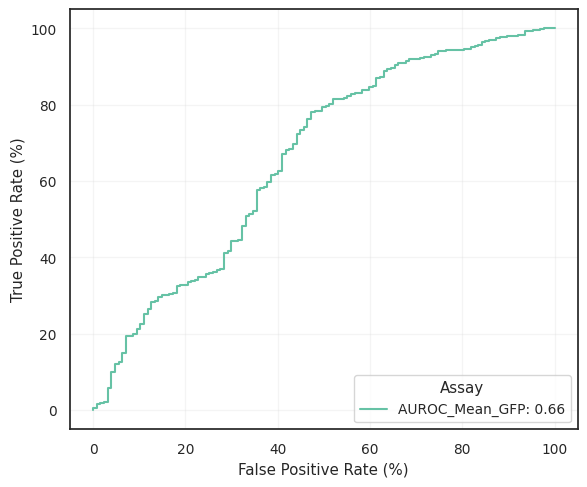

In [71]:
ap_results_dict = plot_auroc_curves(imaging_summary_clinvar, "1_Pathogenic", 
                                    methods=["AUROC_Mean_GFP"])

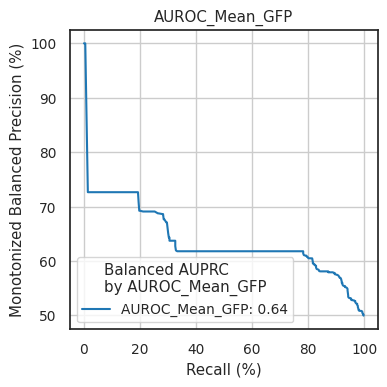

In [72]:
sys.path.insert(1, "../../../../4_compare_ai_scores/2_analysis/scripts")
from yogiroc import *

def plot_adjusted_pr_curves(df_clinvar_w_scores, pos_label, methods, monotonized_flag=True, balanced_flag=True, subsample=False, n_bootstrap=1000, random_state=None):
    """
    For each method, plot the adjusted PR curve (with both balanced and monotonized adjustments)
    and compute the adjusted AUPRC via bootstrapping. Also perform pairwise significance testing 
    of the AUPRC across different RSA categories.
    
    Parameters
    ----------
    df_clinvar_w_scores : Polars DataFrame
        Input data including columns "clinvar_clnsig_clean", category and predictor scores.
    methods : list of str
        List of method names corresponding to score columns in the data.
    set2_palette : list of str
        List of colors (e.g., from a color palette) to use for different RSA categories.
    n_bootstrap : int, optional
        Number of bootstrap iterations for significance testing (default is 1000).
    random_state : int or None, optional
        Seed for reproducibility.
    
    Returns
    -------
    ap_results : dict
        Dictionary of adjusted AUPRC values and bootstrap distributions, structured as:
          { method: { category: {"AP": <adjusted AUPRC>, "boot_ap": <bootstrap array> } } }
    significance : dict
        Dictionary mapping each method to a DataFrame of pairwise p-values comparing AUPRC between categories.
    """
    assert (balanced_flag and not subsample) or (subsample and not balanced_flag) or (not subsample and not balanced_flag)
    
    ap_results_dict = {}
    # sig_results_dict = {}
    fig, axes = plt.subplots(1, len(methods), figsize=(4 * len(methods), 4))
    if len(methods) == 1:
        axes = [axes]
        
    ap_results = {}  # to store adjusted AUPRC and bootstrap distributions
    for m_idx, met in enumerate(methods):
        ap_results[met] = {}
        # Filter data for current category and valid clinical labels.
        df_clin_per_method = df_clinvar_w_scores.filter(
            (pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic", "2_Benign"]))
        ).with_columns(
            (
                pl.when(pl.col("clinvar_clnsig_clean") == pos_label)
                .then(1)
                .otherwise(0)
            ).alias("clinvar_label")
        ).drop_nulls(subset=["clinvar_clnsig_clean", met])

        if pos_label == "2_Benign":
            df_clin_per_method = df_clin_per_method.with_columns(
                (
                    pl.col(met).neg()
                ).alias(met)
            )
        
        # Convert to pandas DataFrame.
        df_pd = df_clin_per_method.to_pandas()
        if subsample:
            # Assume df is your existing DataFrame with a column named "label"
            # Find the minimum count among the two classes (0 and 1)
            min_count = df_pd['clinvar_label'].value_counts().min()
            # Group by the 'label' column and sample min_count rows from each group (without replacement)
            df_pd = df_pd.groupby('clinvar_label').apply(lambda x: x.sample(n=min_count, random_state=42)).reset_index(drop=True)

        # Convert clinvar_label to boolean.
        truth = df_pd["clinvar_label"].astype(bool)
        # Create a scores DataFrame (with one column).
        scores = df_pd[[met]]

        # Create the YogiROC2 object using the new YogiROC2() constructor.
        yrobj = YogiROC2(truth, scores, names=[met], high=True)
        # Get the performance table from the YogiROC2 object.
        table = yrobj.tables[met]

        if (monotonized_flag and balanced_flag):
            table = table.dropna()
        precision = configure_prec(table, monotonized_flag=monotonized_flag, balanced_flag=balanced_flag)
        recall = table["tpr_sens"].values
        # print(precision)
        # print(recall)
        ap = calc_auc(recall[~np.isnan(recall)], precision[~np.isnan(precision)])
        ap_results[met] = {"AUPRC": ap}

        # Plot the adjusted PR curve.
        axes[m_idx].plot(100 * recall, 100 * precision,
                        label=f"{met}: {ap:.2f}")
        # Plot chance level as a horizontal dashed line.
        prior = np.sum(truth) / df_pd.shape[0]
        if (not balanced_flag):
            axes[m_idx].axhline(y=100 * prior, color=set2_palette[plddt_cats.index(cat)], ls="--")
    
        # Customize the subplot.
        handles, labels = axes[methods.index(met)].get_legend_handles_labels()
        precision_label = "Precision (%)"
        title = f"AUPRC\nby {met}"
        
        if balanced_flag:
            precision_label = "Balanced " + precision_label
            title = "Balanced " + title
        if monotonized_flag:
            precision_label = "Monotonized " + precision_label
    
        axes[m_idx].legend(
                        loc="lower left",
                        title=title)
        axes[m_idx].set_xlabel("Recall (%)")
        axes[m_idx].set_ylabel(precision_label)
        axes[m_idx].set_title(met)
        axes[m_idx].grid()

    # sig_results_dict[category] = significance

    plt.tight_layout()
    plt.show()
    # plt.subplots_adjust(wspace=0.04)
    
    return None ## , sig_results_dict

plot_adjusted_pr_curves(imaging_summary_clinvar, "1_Pathogenic", 
                                    methods=["AUROC_Mean_GFP"])

## 4. Gene-level Analyses

In [73]:
def plot_gene_level_summary(total_allele_hit_sum_df, assay, xlim=None, cat="clinvar_clnsig_clean"):
    # Convert to pandas and sort
    total_allele_hit_sum_df = total_allele_hit_sum_df.to_pandas().reset_index(drop=True)
    n_genes = len(total_allele_hit_sum_df)
    
    # Dynamically scale figure size
    fig_height = max(6, min(n_genes * 0.3, 40))
    fig_width = 6  # Slightly wider to accommodate labels
    
    fig, ax = plt.subplots(figsize=(fig_width, fig_height))
    # Create the barplots
    # Total counts (background bars)
    sns.barplot(
        data=total_allele_hit_sum_df, 
        y="symbol", 
        x="total_counts", 
        hue=cat,  # "clinvar_clnsig_clean"
        palette="Set2" if cat not in palette_dict else palette_dict[cat],
        alpha=0.6,  # Make background bars slightly transparent
        ax=ax,
        # gap=.1,
        order=total_allele_hit_sum_df["symbol"].drop_duplicates()
    )
    # Hit counts (foreground bars)
    sns.barplot(
        data=total_allele_hit_sum_df, 
        y="symbol", 
        x="hit_counts", 
        hue=cat,#"clinvar_clnsig_clean", 
        palette="Set2" if cat not in palette_dict else ["orange","forestgreen"],
        ax=ax,
        # gap=.1,
        order=total_allele_hit_sum_df["symbol"].drop_duplicates()
    )
    
    # Add percentage labels
    # Get unique categories and their positions
    categories = total_allele_hit_sum_df[cat].unique()
    n_categories = len(categories)
    
    # Calculate bar positions for each category
    bar_height = 0.8 / n_categories  # Default seaborn bar height divided by number of categories
    
    for i, gene in enumerate(total_allele_hit_sum_df["symbol"].unique()):
        gene_data = total_allele_hit_sum_df[total_allele_hit_sum_df["symbol"] == gene]
        for j, category in enumerate(categories):
            cat_data = gene_data[gene_data[cat] == category]
            if not cat_data.empty:
                # Calculate bar position
                bar_center = i + (j - (n_categories - 1) / 2) * bar_height
                # print(bar_center)
                # print(bar_center)
                # Get the hit percentage value
                hit_perc = cat_data["hit_perc"].iloc[0]
                hit_counts = cat_data["hit_counts"].iloc[0]
                # Add percentage label at the end of the hit_counts bar
                ax.text(
                    hit_counts + max(total_allele_hit_sum_df["hit_counts"]) * 0.01,  # Small offset
                    bar_center,
                    f"{hit_perc:.1f}%",
                    ha="left",
                    va="center",
                    fontsize=9 if n_genes > 20 else 10,
                    fontweight="bold"
                )
    
    # # Formatting
    ax.grid(alpha=0.2, axis='x')
    ax.set_xlabel("Count", fontsize=11)
    ax.set_ylabel("Gene Symbol", fontsize=11)
    ax.set_title(f"{assay}", fontsize=13)
    
    # # Adjust x-axis limit to accommodate labels
    # max_count = max(total_allele_hit_sum_df["total_counts"].max(), 
    #                 total_allele_hit_sum_df["hit_counts"].max())
    # ax.set_xlim(0, max_count * 1.15)
    
    # Improve legend
    handles, labels = ax.get_legend_handles_labels()
    # Remove duplicate legend entries (seaborn creates duplicates with multiple barplots)
    unique_labels = []
    unique_handles = []
    for handle, label in zip(handles, labels):
        if label not in unique_labels:
            unique_labels.append(label)
            unique_handles.append(handle)
    
    ax.legend(unique_handles, unique_labels, 
              title=cat, 
              fontsize=10, 
              loc="lower right",
              framealpha=0.9)
    if xlim:
        ax.set_xlim(xlim)
        
    plt.tight_layout()
    plt.show()
    
    return total_allele_hit_sum_df

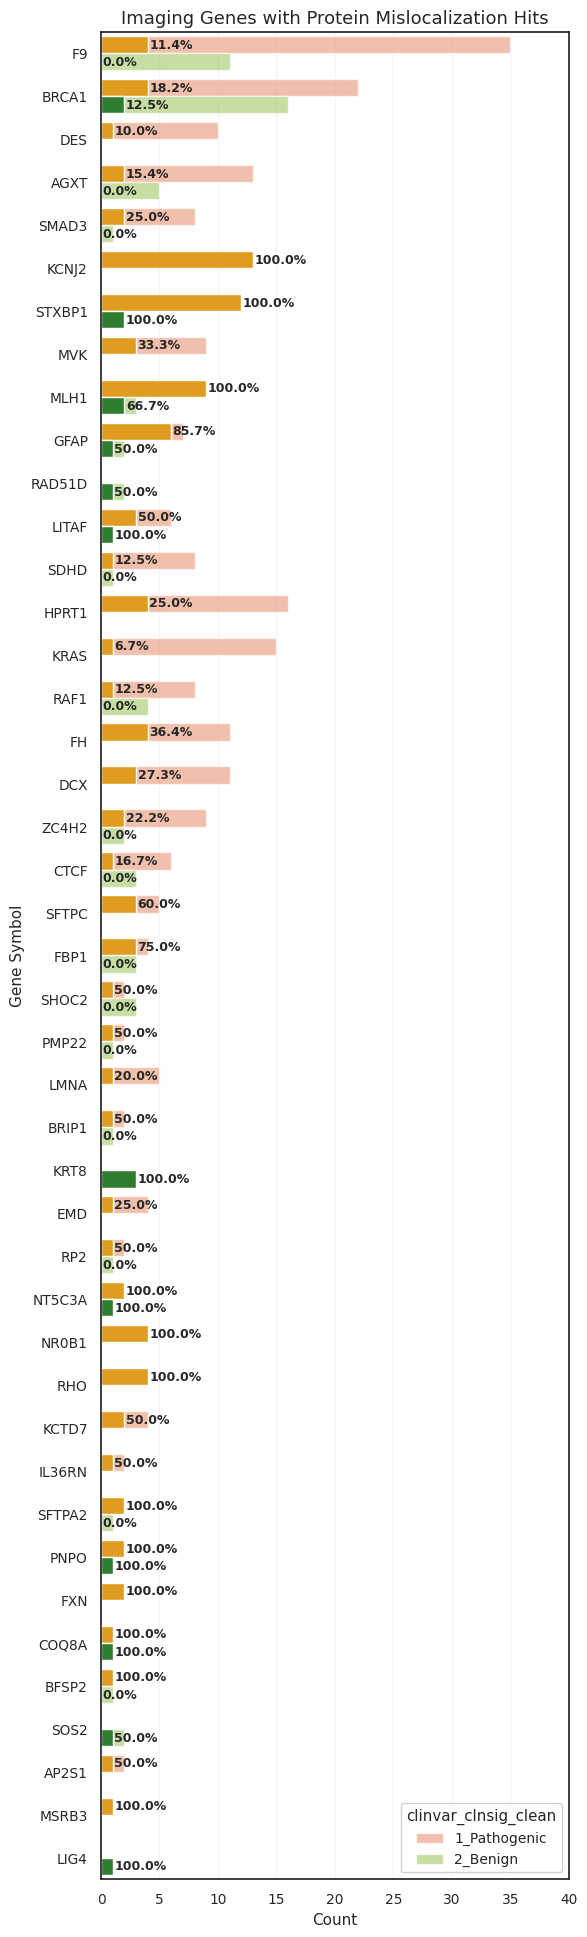

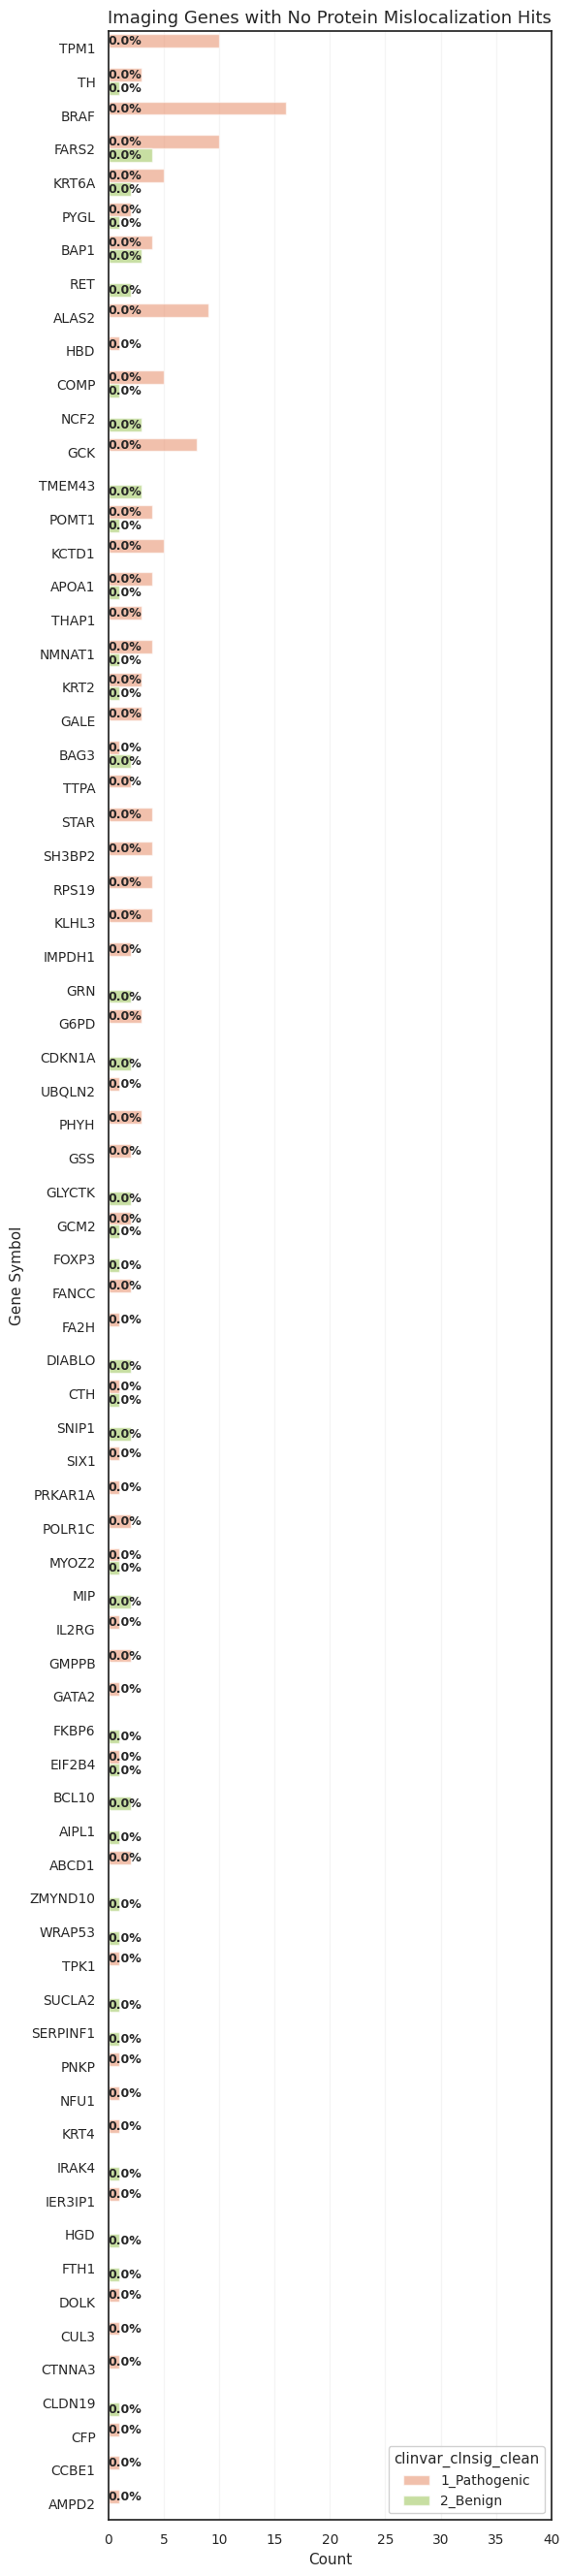

In [74]:
dual_gene = imaging_summary_clinvar.group_by(
    ["symbol"]
).len().rename(
    {"len": "total_counts_all"}
).sort("total_counts_all", descending=True)

dual_clean_all = imaging_summary_clinvar.filter(
    pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign"]) ## ,"3_Conflicting","4_VUS"
).group_by(
    ["symbol","clinvar_clnsig_clean"]
).len().rename(
    {"len": "total_counts"}
)

dual_clean_hits_all = imaging_summary_clinvar.filter(
    (pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign"])) & (pl.col(GFP_MISLOCAL_FEAT)==1) ##,"3_Conflicting","4_VUS"
).group_by(
    ["symbol","clinvar_clnsig_clean"]
).len().rename(
    {"len": "hit_counts"}
)

dual_hits_all = dual_clean_all.join(
    dual_clean_hits_all,
    on=["symbol","clinvar_clnsig_clean"],
    how="left"
).fill_null(0).with_columns(
    (pl.col("hit_counts") / pl.col("total_counts") * 100).alias("hit_perc")
).join(dual_gene, on="symbol").sort(
    "total_counts_all","symbol","clinvar_clnsig_clean", 
    descending=[True, True, False]
)
genes_with_hits = dual_hits_all.filter(pl.col("hit_perc")>0)["symbol"].unique()

dual_hits_all_res = plot_gene_level_summary(dual_hits_all.filter(pl.col("symbol").is_in(genes_with_hits)), 
                                            "Imaging Genes with Protein Mislocalization Hits", xlim=(0,40))
dual_hits_no_res = plot_gene_level_summary(dual_hits_all.filter(~pl.col("symbol").is_in(genes_with_hits)).sort(
    "total_counts_all","symbol","clinvar_clnsig_clean", 
    descending=[True, True, False]
), "Imaging Genes with No Protein Mislocalization Hits", xlim=(0,40))